# COVID-19 en Estados Unidos: qué cambia cuando los números se miran con calma

Análisis exploratorio del histórico diario del [COVID Tracking Project](https://covidtracking.com/data/download), enriquecido con la población estatal del censo de EE. UU. a 1 de julio de 2020.

El archivo termina el **7 de marzo de 2021**. No describe la pandemia completa: describe lo que se sabía, con la calidad de datos de entonces, hasta ese día.

## Preguntas

1. Si se ordenan los estados por muertes totales, ¿se está midiendo la gravedad o el tamaño del estado?
2. ¿La peor ola fue la de primavera de 2020?
3. ¿Más casos por habitante significaron más muertes por habitante?
4. ¿Qué partes del archivo no sirven para tomar una decisión?

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns
from IPython.display import Markdown, display

def encontrar_raiz() -> Path:
    aqui = Path.cwd().resolve()
    for candidato in [aqui, *aqui.parents]:
        if (candidato / "src" / "limpieza.py").exists():
            return candidato
    raise FileNotFoundError("Abre el notebook desde la carpeta del proyecto.")

ROOT = encontrar_raiz()
sys.path.insert(0, str(ROOT / "src"))

from cargar import cargar_covid, cargar_poblacion
from limpieza import (
    DIAS_SEMANA,
    anadir_variables,
    columna_duplicada,
    limites_iqr,
    mascara_atipicos,
    media_movil,
    preparar_columnas,
)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["figure.dpi"] = 120
pd.set_option("display.max_columns", 24)
pd.set_option("display.float_format", lambda valor: f"{valor:,.2f}")

FIG = ROOT / "reports" / "figuras"
FIG.mkdir(parents=True, exist_ok=True)

COLORES_REGION = {
    "Noreste": "#b45309",
    "Medio Oeste": "#0369a1",
    "Sur": "#be123c",
    "Oeste": "#0f766e",
    "Puerto Rico": "#6b7280",
}
REGIONES = ["Noreste", "Medio Oeste", "Sur", "Oeste"]

def guardar(fig, nombre: str) -> None:
    fig.savefig(FIG / nombre, dpi=140, bbox_inches="tight")
    plt.show()

## 1. Carga y estructura

La API se consulta una sola vez. El resultado queda en `data/raw/covid_states_daily.csv` y las siguientes ejecuciones leen ese archivo. El mismo recorrido, de un comando, está en `scripts/pipeline.py`.

In [2]:
crudo = cargar_covid(ROOT / "data" / "raw" / "covid_states_daily.csv")
print(f"Filas: {crudo.shape[0]:,}".replace(",", "."))
print(f"Columnas: {crudo.shape[1]}")
print(f"Jurisdicciones: {crudo['state'].nunique()}")
crudo.head(3)

Filas: 20.780
Columnas: 56
Jurisdicciones: 56


,date,state,positive,probableCases,negative,pending,totalTestResultsSource,totalTestResults,hospitalizedCurrently,hospitalizedCumulative,inIcuCurrently,inIcuCumulative,...,totalTestResultsIncrease,posNeg,dataQualityGrade,deathIncrease,hospitalizedIncrease,hash,commercialScore,negativeRegularScore,negativeScore,positiveScore,score,grade
0,20210307,AK,"56,886.00",NaN,NaN,NaN,totalTestsViral,"1,731,628.00",33.00,"1,293.00",NaN,NaN,...,0,56886,NaN,0,0,dc4bccd4bb885349d7e94d6fed058e285d4be164,0,0,0,0,0,NaN
1,20210307,AL,"499,819.00","107,742.00","1,931,711.00",NaN,totalTestsPeopleViral,"2,323,788.00",494.00,"45,976.00",NaN,"2,676.00",...,2347,2431530,NaN,-1,0,997207b430824ea40b8eb8506c19a93e07bc972e,0,0,0,0,0,NaN
2,20210307,AR,"324,818.00","69,092.00","2,480,716.00",NaN,totalTestsViral,"2,736,442.00",335.00,"14,926.00",141.00,NaN,...,3380,2805534,NaN,22,11,50921aeefba3e30d31623aa495b47fb2ecc72fae,0,0,0,0,0,NaN


In [3]:
crudo.info()

<class 'pandas.DataFrame'>
RangeIndex: 20780 entries, 0 to 20779
Data columns (total 56 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   date                         20780 non-null  int64  
 1   state                        20780 non-null  str    
 2   positive                     20592 non-null  float64
 3   probableCases                9271 non-null   float64
 4   negative                     13290 non-null  float64
 5   pending                      2138 non-null   float64
 6   totalTestResultsSource       20780 non-null  str    
 7   totalTestResults             20614 non-null  float64
 8   hospitalizedCurrently        17339 non-null  float64
 9   hospitalizedCumulative       12382 non-null  float64
 10  inIcuCurrently               11636 non-null  float64
 11  inIcuCumulative              3789 non-null   float64
 12  onVentilatorCurrently        9126 non-null   float64
 13  onVentilatorCumulative     

In [4]:
columnas_clave = [
    "positive",
    "death",
    "hospitalizedCurrently",
    "totalTestResults",
    "positiveIncrease",
    "deathIncrease",
]
crudo[columnas_clave].describe().T

,count,mean,std,min,25%,50%,75%,max
positive,"20,592.00","165,155.97","326,785.24",0.00,"5,753.75","46,064.50","177,958.00","3,501,394.00"
death,"19,930.00","3,682.22","6,281.37",0.00,161.25,"1,108.00","4,387.50","54,124.00"
hospitalizedCurrently,"17,339.00","1,190.58","2,060.04",0.00,166.50,531.00,"1,279.00","22,851.00"
totalTestResults,"20,614.00","2,186,935.75","4,436,508.15",0.00,"104,049.75","655,267.00","2,264,766.50","49,646,014.00"
positiveIncrease,"20,780.00","1,383.85","3,023.56","-7,757.00",65.00,435.00,"1,335.25","71,734.00"
deathIncrease,"20,780.00",24.79,60.16,-201.00,0.00,6.00,24.00,"2,559.00"


## 2. Valores faltantes, duplicados y tipos

`date` llega como un entero (`20200313`), no como fecha. Varias columnas de detalle (pruebas de anticuerpos, ventiladores acumulados, altas hospitalarias) están vacías en la mayor parte de las filas: no dan para comparar estados. Otras columnas parecen completas y no dicen nada: `grade` está vacío y las puntuaciones internas (`score` y similares) valen siempre cero.

In [5]:
nulos = (crudo.isna().mean() * 100).sort_values(ascending=False)
print("Filas duplicadas:", int(crudo.duplicated().sum()))
print("Duplicados de estado + fecha:", int(crudo.duplicated(['state', 'date']).sum()))
print("hospitalized es copia de hospitalizedCumulative:", columna_duplicada(crudo, "hospitalized", "hospitalizedCumulative"))
print()
for columna in ["grade", "score", "commercialScore", "dataQualityGrade"]:
    print(f"{columna}: {crudo[columna].nunique(dropna=False)} valores distintos -> {crudo[columna].unique()[:3]}")

nulos[nulos > 0].head(20).to_frame("% nulos")

Filas duplicadas: 0
Duplicados de estado + fecha: 0
hospitalized es copia de hospitalizedCumulative: True

grade: 1 valores distintos -> [nan]
score: 1 valores distintos -> [0]
commercialScore: 1 valores distintos -> [0]
dataQualityGrade: 1 valores distintos -> [nan]


,% nulos
grade,100.00
dataQualityGrade,100.00
positiveTestsPeopleAntigen,96.95
negativeTestsPeopleAntibody,95.32
totalTestsPeopleAntigen,95.19
positiveTestsPeopleAntibody,94.74
onVentilatorCumulative,93.79
negativeTestsAntibody,92.98
pending,89.71
totalTestsPeopleAntibody,89.41


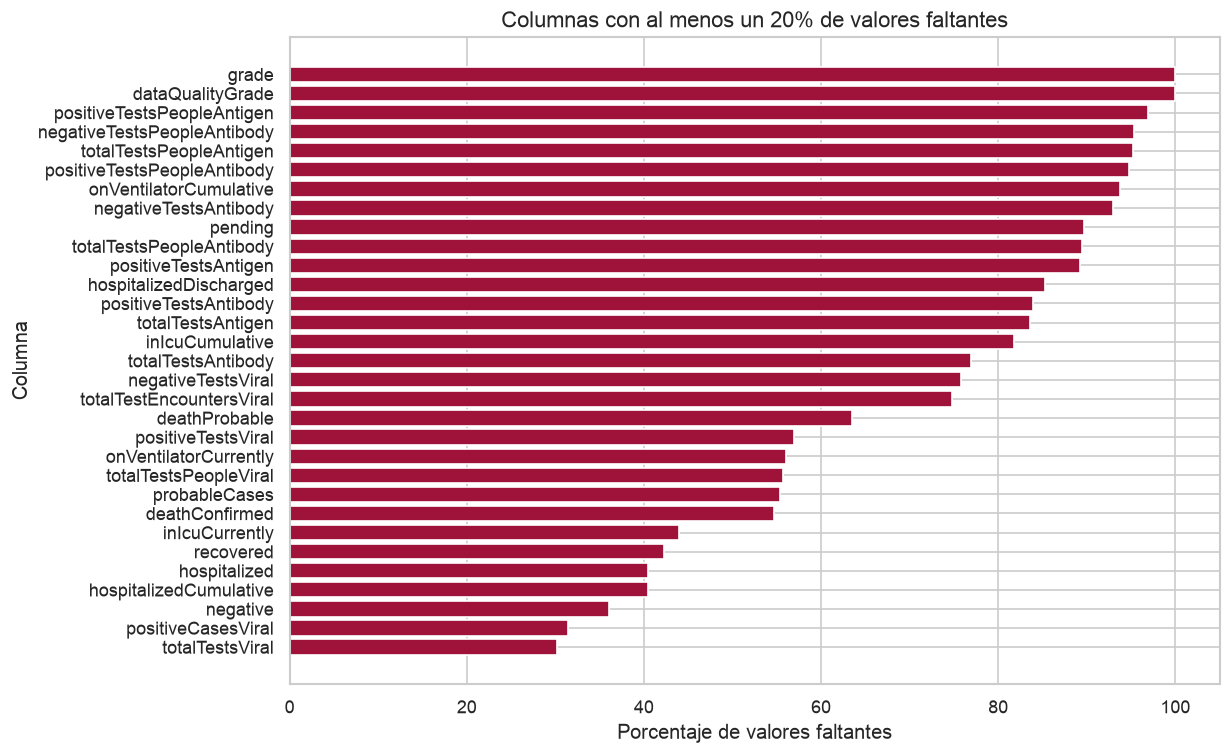

In [6]:
visibles = nulos[nulos >= 20].sort_values()
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(visibles.index, visibles.values, color="#9f1239")
ax.set_xlabel("Porcentaje de valores faltantes")
ax.set_ylabel("Columna")
ax.set_title("Columnas con al menos un 20% de valores faltantes")
guardar(fig, "01_nulos.png")

## 3. Decisiones de limpieza

No se elimina ninguna fila.

- **Metadatos.** Hash, marcas de tiempo de la descarga, `grade` vacío y puntuaciones internas en cero no describen la pandemia.
- **Columnas con más del 80% de nulos.** No hay base para comparar estados. Imputarlas fabricaría información.
- **`hospitalized`.** Es idéntica a `hospitalizedCumulative` en todas las filas donde ambas tienen valor. Se deja la de nombre explícito.
- **Nulos que se quedan.** `death` y `positive` fallan en pocos días y no se rellenan con cero: un cero significaría «ese día no hubo muertes» y no es lo que dice el dato ausente. `hospitalizedCurrently` falta cuando el estado no informó; poner la mediana crearía pacientes que nadie contó.
- **Incrementos negativos.** Un `deathIncrease` negativo es una corrección contable, no una persona que vuelve a la vida. Hay que conservarlo: solo así la suma de los incrementos cuadra con las muertes acumuladas del último día.

La población (segunda fuente) es la estimación del Census Bureau a 1 de julio de 2020. Permite pasar de totales a tasas por 100.000 habitantes. Samoa Americana, Guam, Islas Marianas del Norte e Islas Vírgenes no vienen en ese archivo y quedan fuera de las tasas.

In [7]:
limpio, informe = preparar_columnas(crudo)
poblacion = cargar_poblacion(ROOT / "data" / "external" / "nst-est2020-alldata.csv")
df = anadir_variables(limpio.merge(poblacion, on="state", how="left"))

print(f"Filas antes y después: {len(crudo):,} -> {len(df):,}".replace(",", "."))
print(f"Columnas: {crudo.shape[1]} -> {df.shape[1]}")
print("Metadato eliminado:", ", ".join(informe["metadato"]))
print("Casi vacías eliminadas:", ", ".join(informe["casi_vacias"]))
print("Duplicadas eliminadas:", ", ".join(informe["duplicadas"]))
sin_poblacion = sorted(df.loc[df["poblacion_2020"].isna(), "state"].unique())
print("Sin población del censo:", sin_poblacion)
df[["state", "nombre", "fecha", "positive", "death", "muertes_por_100k"]].dtypes

Filas antes y después: 20.780 -> 20.780
Columnas: 56 -> 48
Metadato eliminado: hash, grade, dataQualityGrade, commercialScore, negativeRegularScore, negativeScore, positiveScore, score, lastUpdateEt, dateModified, checkTimeEt, dateChecked
Casi vacías eliminadas: pending, inIcuCumulative, onVentilatorCumulative, hospitalizedDischarged, positiveTestsAntibody, negativeTestsAntibody, totalTestsPeopleAntibody, positiveTestsPeopleAntibody, negativeTestsPeopleAntibody, totalTestsPeopleAntigen, positiveTestsPeopleAntigen, totalTestsAntigen, positiveTestsAntigen
Duplicadas eliminadas: hospitalized
Sin población del censo: ['AS', 'GU', 'MP', 'VI']


state                          str
nombre                         str
fecha               datetime64[us]
positive                   float64
death                      float64
muertes_por_100k           float64
dtype: object

## 4. Valores atípicos

El rango intercuartílico marca como atípico cualquier incremento diario de muertes por encima de unas pocas decenas. Esos días no son errores de tecleo: son el pico de las olas y los días en que un estado vuelca varios días de retraso. Quitarlos borraría justo el acontecimiento que queremos medir.

La misma regla sirve para ver las correcciones negativas, que caen por debajo de la valla inferior. Se quedan en la serie, marcadas, y no entran en una media diaria ingenua: para leer la tendencia se usa la media de 7 días.

Valla superior del IQR: 60
Días estado marcados como atípicos: 2.208 de 20.780
Esos días, por mes:
mes
2020-10     72
2020-11    147
2020-12    427
2021-01    447
2021-02    319
2021-03     51
dtype: int64
Correcciones negativas en deathIncrease: 73
Suma de esas correcciones: -1043


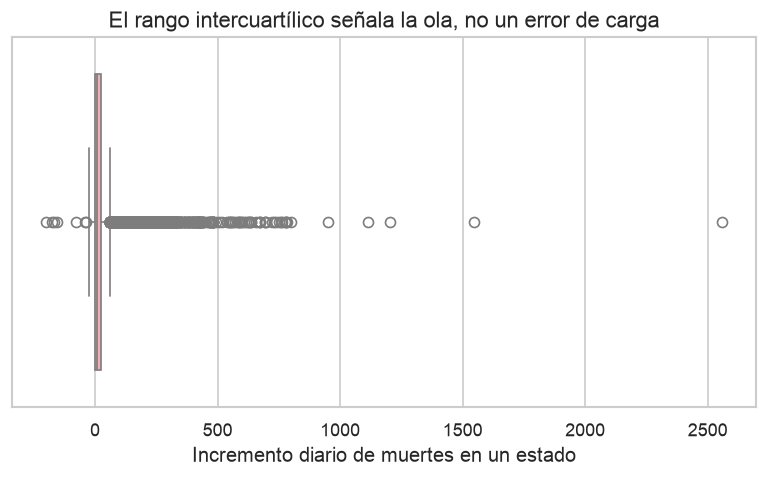

In [8]:
atipicos = mascara_atipicos(df["deathIncrease"])
_, valla = limites_iqr(df["deathIncrease"])
print(f"Valla superior del IQR: {valla:.0f}")
print(f"Días estado marcados como atípicos: {int(atipicos.sum()):,} de {len(df):,}".replace(",", "."))
print("Esos días, por mes:")
print(df.loc[atipicos].groupby("mes").size().tail(6))
print(f"Correcciones negativas en deathIncrease: {int((df['deathIncrease'] < 0).sum())}")
print(f"Suma de esas correcciones: {int(df.loc[df['deathIncrease'] < 0, 'deathIncrease'].sum())}")

fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(x=df["deathIncrease"], ax=ax, color="#fda4af")
ax.set_xlabel("Incremento diario de muertes en un estado")
ax.set_title("El rango intercuartílico señala la ola, no un error de carga")
guardar(fig, "02_boxplot_incremento_muertes.png")

## 5. Variables nuevas

Sobre la tabla limpia se construyen:

- `mes` y `dia_semana`, a partir de la fecha ya convertida.
- `muertes_por_100k`, `casos_por_100k`, `pruebas_por_100k` y `hospitalizados_por_100k`: el acumulado (o la cifra del día, en hospitalizados) dividido por la población y multiplicado por 100.000.
- `letalidad_aparente`: muertes acumuladas entre casos acumulados. No es una letalidad clínica. Solo mide qué proporción de los casos detectados había muerto hasta ese día, y depende de cuánto se diagnosticara.
- `positividad_acumulada`: casos entre pruebas, con la cautela de que los estados no cuentan las pruebas con la misma definición.

## 6. Análisis univariado

Las tres lecturas de una sola variable: cómo se reparte la mortalidad por habitante al cierre del archivo, cómo son los incrementos diarios de muertes, y qué definición de «prueba» usa cada fila. Esta última no es un detalle técnico: `totalTestResults` mezcla cuatro formas distintas de contar.

Foto del 2021-03-07: 52 jurisdicciones con población


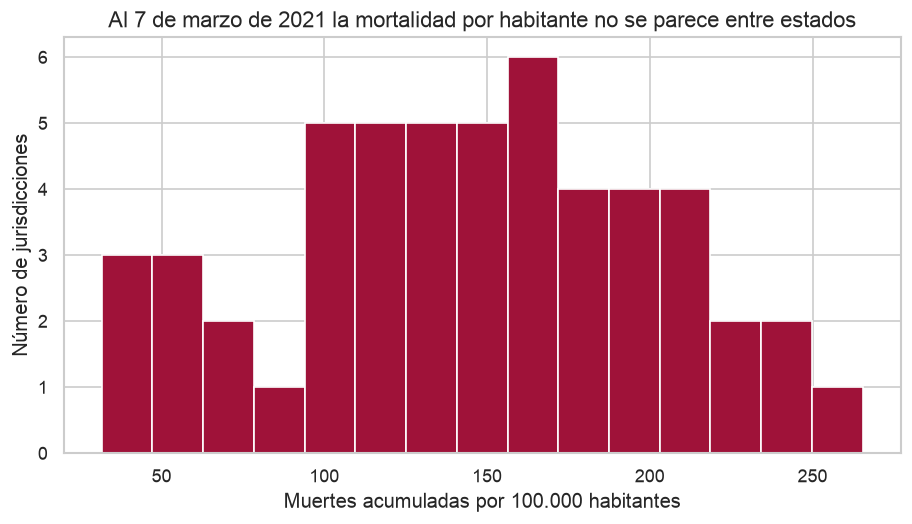

In [9]:
foto = df[df["fecha"] == df["fecha"].max()].dropna(subset=["muertes_por_100k"]).copy()
print(f"Foto del {foto['fecha'].iloc[0].date()}: {len(foto)} jurisdicciones con población")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(foto["muertes_por_100k"], bins=15, color="#9f1239", edgecolor="white")
ax.set_xlabel("Muertes acumuladas por 100.000 habitantes")
ax.set_ylabel("Número de jurisdicciones")
ax.set_title("Al 7 de marzo de 2021 la mortalidad por habitante no se parece entre estados")
guardar(fig, "03_hist_muertes_100k.png")

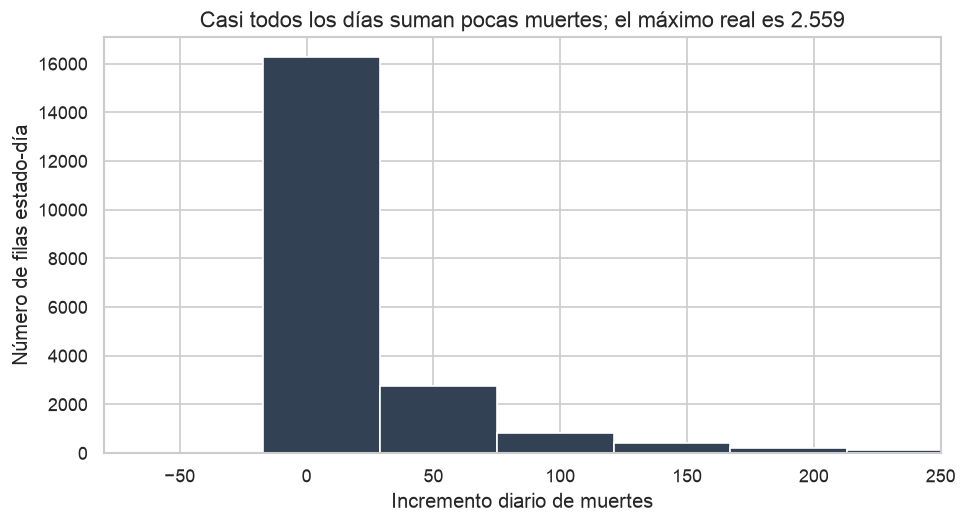

In [10]:
maximo = int(df["deathIncrease"].max())
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(df["deathIncrease"], bins=60, color="#334155", edgecolor="white")
ax.set_xlim(-80, 250)
ax.set_xlabel("Incremento diario de muertes")
ax.set_ylabel("Número de filas estado-día")
ax.set_title(f"Casi todos los días suman pocas muertes; el máximo real es {maximo:,}".replace(",", "."))
guardar(fig, "04_hist_incremento_muertes.png")

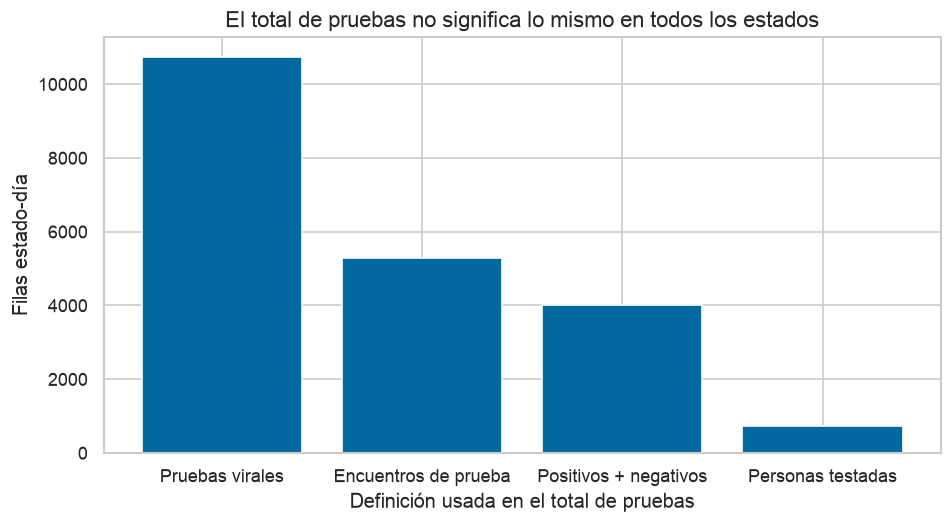

In [11]:
nombres_fuente = {
    "totalTestsViral": "Pruebas virales",
    "totalTestEncountersViral": "Encuentros de prueba",
    "posNeg": "Positivos + negativos",
    "totalTestsPeopleViral": "Personas testadas",
}
conteo = df["totalTestResultsSource"].map(nombres_fuente).value_counts()
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(conteo.index, conteo.values, color="#0369a1")
ax.set_ylabel("Filas estado-día")
ax.set_xlabel("Definición usada en el total de pruebas")
ax.set_title("El total de pruebas no significa lo mismo en todos los estados")
guardar(fig, "05_definicion_pruebas.png")

## 7. Análisis bivariado

Tres relaciones: casos y muertes ya en tasa (para que California no gane por tener 39 millones de habitantes), población y muertes en escala logarítmica (la trampa del tamaño) y la mortalidad por habitante según la región del censo. El Distrito de Columbia va con el Sur porque así lo agrupa el Census Bureau, no por una decisión de este análisis. Puerto Rico no entra en el diagrama de caja: es una sola jurisdicción y una caja con un solo valor no resume nada. Su tasa al cierre es de 65 muertes por 100.000.

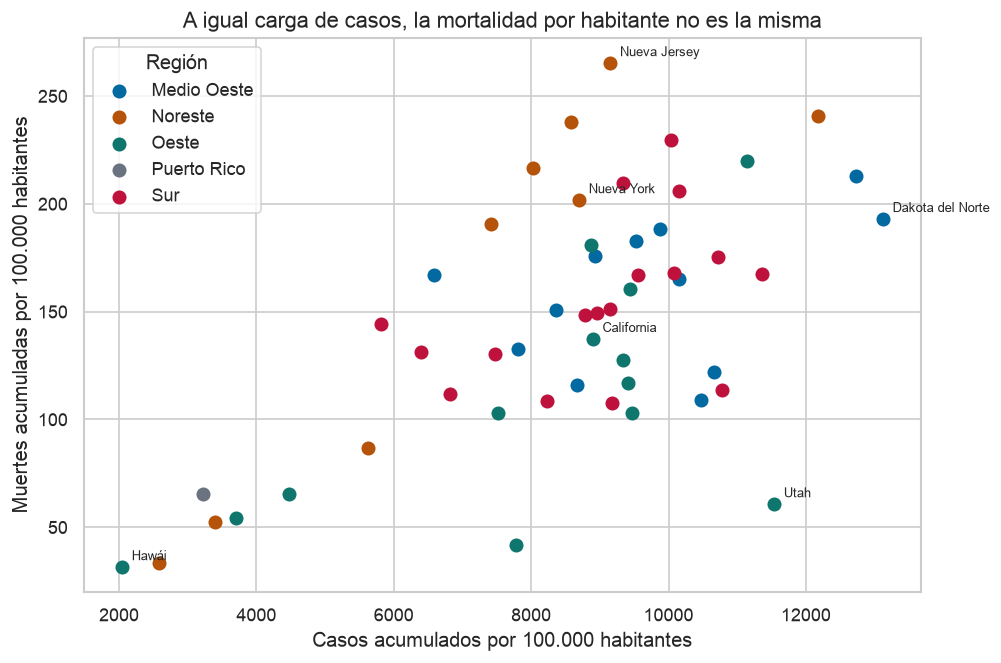

In [12]:
fig, ax = plt.subplots(figsize=(9, 6))
for region, grupo in foto.groupby("region"):
    ax.scatter(
        grupo["casos_por_100k"],
        grupo["muertes_por_100k"],
        label=region,
        color=COLORES_REGION[region],
        s=55,
    )
for sigla in ["NJ", "NY", "CA", "UT", "HI", "ND"]:
    fila = foto.loc[foto["state"] == sigla].iloc[0]
    ax.annotate(fila["nombre"], (fila["casos_por_100k"], fila["muertes_por_100k"]), fontsize=8, xytext=(6, 4), textcoords="offset points")
ax.set_xlabel("Casos acumulados por 100.000 habitantes")
ax.set_ylabel("Muertes acumuladas por 100.000 habitantes")
ax.set_title("A igual carga de casos, la mortalidad por habitante no es la misma")
ax.legend(title="Región")
guardar(fig, "06_casos_vs_muertes_100k.png")

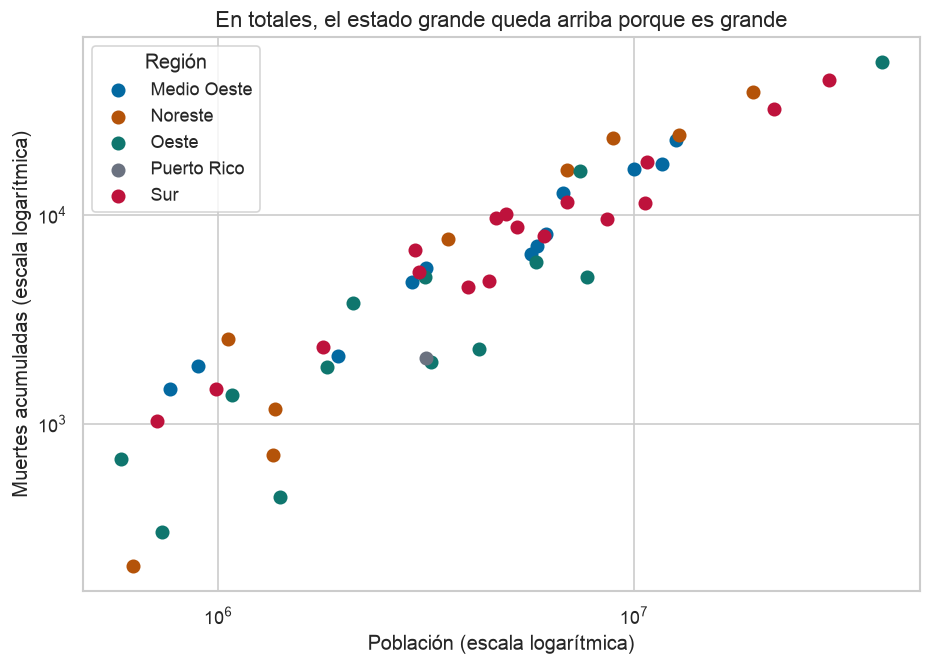

In [13]:
fig, ax = plt.subplots(figsize=(9, 6))
for region, grupo in foto.groupby("region"):
    ax.scatter(grupo["poblacion_2020"], grupo["death"], label=region, color=COLORES_REGION[region], s=55)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Población (escala logarítmica)")
ax.set_ylabel("Muertes acumuladas (escala logarítmica)")
ax.set_title("En totales, el estado grande queda arriba porque es grande")
ax.legend(title="Región")
guardar(fig, "07_tamano_vs_muertes.png")

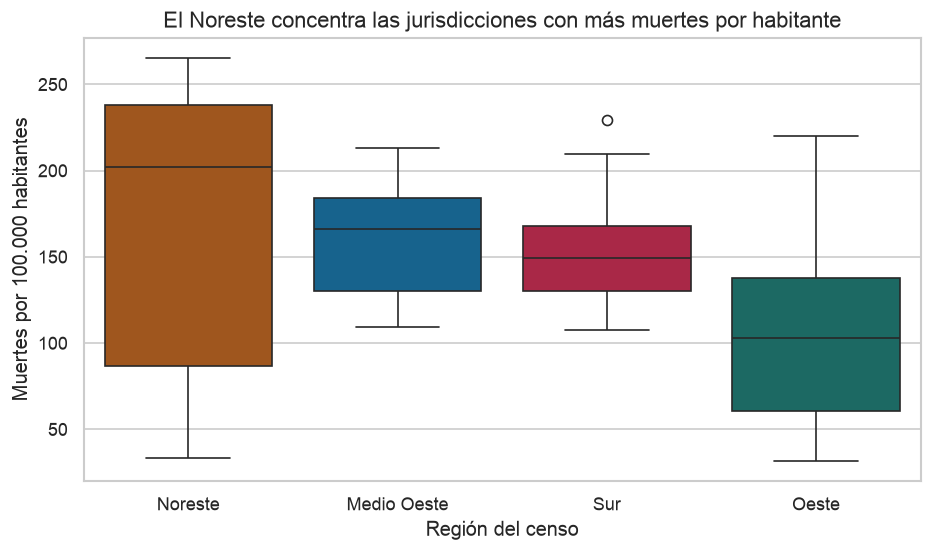

In [14]:
foto_regiones = foto[foto["region"].isin(REGIONES)]
orden = foto_regiones.groupby("region")["muertes_por_100k"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(9, 4.8))
sns.boxplot(
    data=foto_regiones,
    x="region",
    y="muertes_por_100k",
    order=orden,
    hue="region",
    palette=COLORES_REGION,
    legend=False,
    ax=ax,
)
ax.set_xlabel("Región del censo")
ax.set_ylabel("Muertes por 100.000 habitantes")
ax.set_title("El Noreste concentra las jurisdicciones con más muertes por habitante")
guardar(fig, "08_boxplot_region.png")

## 8. Agregados

`groupby` resume el último día por región. La tabla dinámica parte las muertes nuevas entre 2020 y 2021: 2021 solo contiene hasta el 7 de marzo, así que su columna no es un año completo. Aun así, en dos meses y una semana de 2021 ya hay del orden de la mitad de las muertes de todo 2020. El detalle mensual está debajo.

In [15]:
habitantes = foto.drop_duplicates("state").groupby("region")["poblacion_2020"].sum()
por_region = foto.groupby("region").agg(
    jurisdicciones=("state", "nunique"),
    muertes=("death", "sum"),
    casos=("positive", "sum"),
)
por_region["muertes_por_100k"] = por_region["muertes"] / habitantes * 100_000
por_region["casos_por_100k"] = por_region["casos"] / habitantes * 100_000
por_region.sort_values("muertes_por_100k", ascending=False)

,jurisdicciones,muertes,casos,muertes_por_100k,casos_por_100k
region,,,,,
Noreste,9,"115,718.00","4,586,626.00",207.19,"8,212.42"
Medio Oeste,12,"107,743.00","6,087,699.00",157.71,"8,910.99"
Sur,17,"190,177.00","11,431,707.00",150.14,"9,025.31"
Oeste,13,"99,291.00","6,538,217.00",126.24,"8,312.55"
Puerto Rico,1,"2,062.00","101,632.00",65.27,"3,216.87"


In [16]:
pivot = (
    df[df["region"].isin(REGIONES)]
    .pivot_table(index="region", columns="anio", values="deathIncrease", aggfunc="sum")
)
pivot

anio,2020,2021
region,,
Medio Oeste,75325,32418
Noreste,86529,29189
Oeste,54119,45172
Sur,119179,70998


In [17]:
por_mes = df.groupby("mes", as_index=False).agg(
    muertes=("deathIncrease", "sum"),
    casos=("positiveIncrease", "sum"),
    pruebas=("totalTestResultsIncrease", "sum"),
)
por_mes["positividad"] = por_mes["casos"] / por_mes["pruebas"].where(por_mes["pruebas"] > 0)
por_mes

,mes,muertes,casos,pruebas,positividad
0,2020-01,0,2,6,0.33
1,2020-02,5,16,6542,0.00
2,2020-03,4326,196851,1176184,0.17
3,2020-04,55315,876279,5502666,0.16
4,2020-05,41137,718205,11513568,0.06
5,2020-06,19475,831597,16762678,0.05
6,2020-07,25249,1900180,25787479,0.07
7,2020-08,30244,1457213,25498993,0.06
8,2020-09,23329,1192663,27530527,0.04
9,2020-10,23545,1892015,36566898,0.05


## 9. Correlación

Correlacionar casos y muertes en bruto, el 7 de marzo, da un coeficiente altísimo. Las dos cifras crecen con la población: el heatmap de la izquierda mide el tamaño del estado.

El de la derecha usa tasas por habitante y la letalidad aparente. La relación baja, y la letalidad aparente casi no se mueve con los casos por habitante. Hacer muchos tests y detectar muchos casos no es lo mismo que morir más.

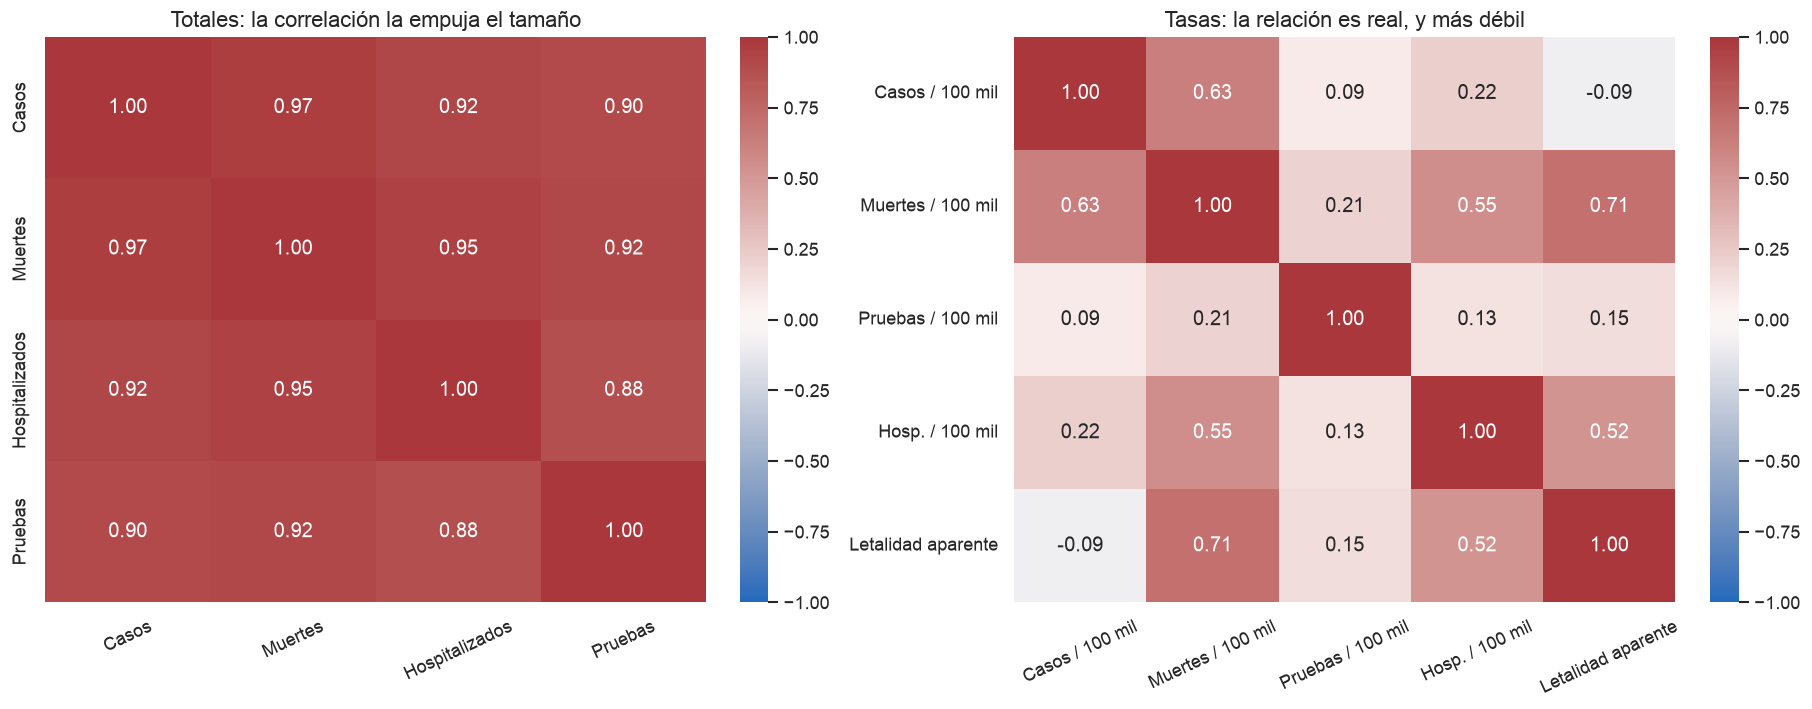

In [18]:
nombres_abs = {
    "positive": "Casos",
    "death": "Muertes",
    "hospitalizedCurrently": "Hospitalizados",
    "totalTestResults": "Pruebas",
}
nombres_tasa = {
    "casos_por_100k": "Casos / 100 mil",
    "muertes_por_100k": "Muertes / 100 mil",
    "pruebas_por_100k": "Pruebas / 100 mil",
    "hospitalizados_por_100k": "Hosp. / 100 mil",
    "letalidad_aparente": "Letalidad aparente",
}
corr_abs = foto[["positive", "death", "hospitalizedCurrently", "totalTestResults"]].corr().rename(index=nombres_abs, columns=nombres_abs)
corr_tasa = foto[list(nombres_tasa)].corr().rename(index=nombres_tasa, columns=nombres_tasa)

fig, ejes = plt.subplots(1, 2, figsize=(15, 5.8), constrained_layout=True)
sns.heatmap(corr_abs, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=ejes[0])
sns.heatmap(corr_tasa, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=ejes[1])
ejes[0].set_title("Totales: la correlación la empuja el tamaño")
ejes[1].set_title("Tasas: la relación es real, y más débil")
for eje in ejes:
    eje.tick_params(axis="x", labelrotation=25)
guardar(fig, "09_heatmaps.png")

## 10. Tendencia y media móvil de 7 días

Las muertes diarias del país bajan en domingo y lunes: el parte no llega el fin de semana y aparece el martes. Una media de un solo día confunde el calendario de publicación con la epidemia. La media de 7 días reparte ese retraso.

La positividad de los primeros días de marzo de 2020 se dispara porque casi no había pruebas (el denominador es diminuto). El gráfico de positividad empieza el 15 de marzo, cuando ya hay un denominador interpretable. También aquí el denominador mezcla definiciones de prueba, así que la cifra es una señal, no un porcentaje de laboratorio.

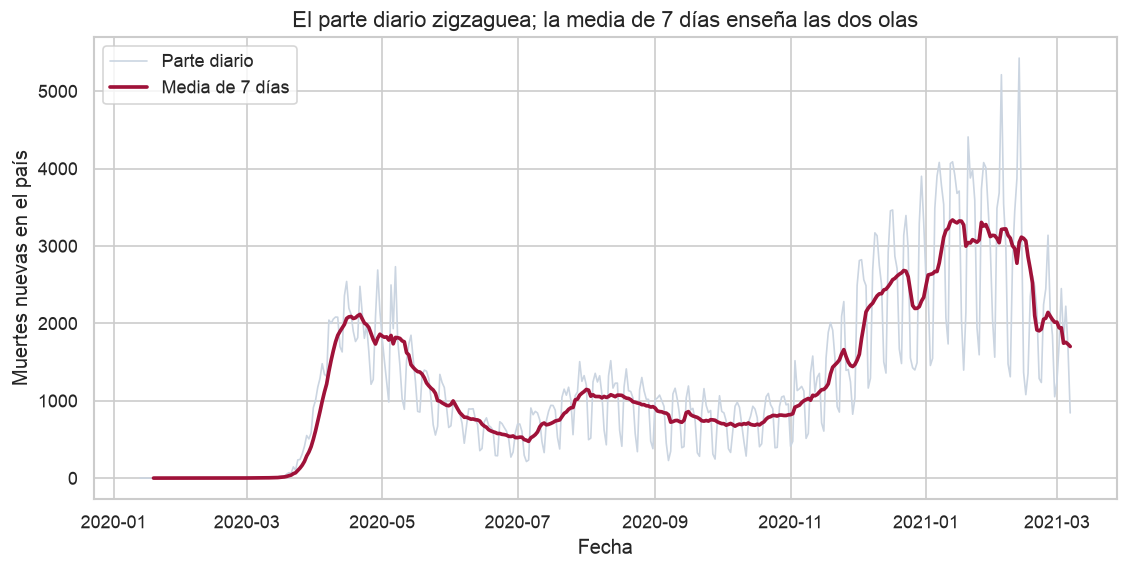

In [19]:
nacional = (
    df.groupby("fecha", as_index=False)
    .agg(
        muertes=("deathIncrease", "sum"),
        casos=("positiveIncrease", "sum"),
        pruebas=("totalTestResultsIncrease", "sum"),
        hospitalizados=("hospitalizedCurrently", "sum"),
        estados_con_hospitalizados=("hospitalizedCurrently", "count"),
        jurisdicciones=("state", "nunique"),
    )
    .sort_values("fecha")
)
nacional["muertes_mm7"] = media_movil(nacional["muertes"], 7)
nacional["casos_mm7"] = media_movil(nacional["casos"], 7)
suma_casos = nacional["casos"].rolling(7).sum()
suma_pruebas = nacional["pruebas"].rolling(7).sum()
nacional["positividad_7d"] = suma_casos.where(suma_pruebas > 0) / suma_pruebas.where(suma_pruebas > 0)
nacional["dia_semana"] = nacional["fecha"].dt.day_name().map(DIAS_SEMANA)

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(nacional["fecha"], nacional["muertes"], color="#cbd5e1", linewidth=1, label="Parte diario")
ax.plot(nacional["fecha"], nacional["muertes_mm7"], color="#9f1239", linewidth=2.2, label="Media de 7 días")
ax.set_xlabel("Fecha")
ax.set_ylabel("Muertes nuevas en el país")
ax.set_title("El parte diario zigzaguea; la media de 7 días enseña las dos olas")
ax.legend()
guardar(fig, "10_serie_muertes.png")

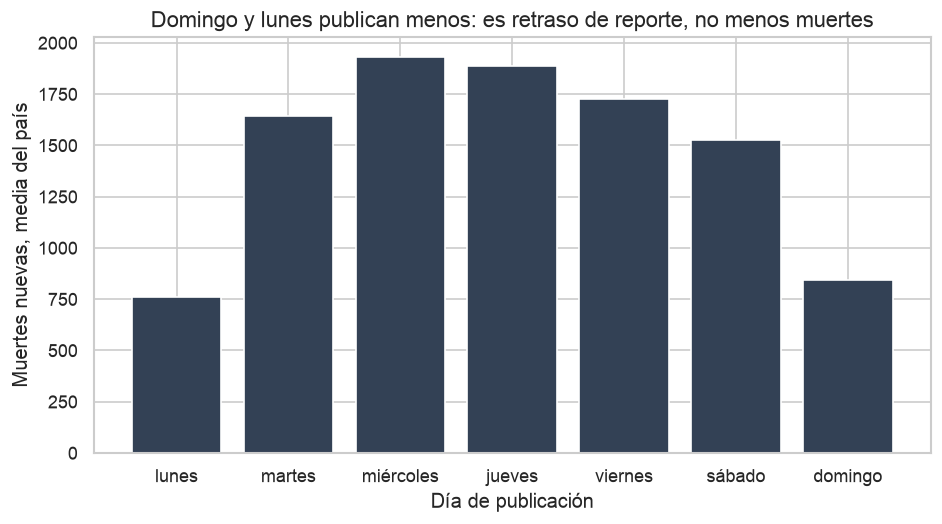

In [20]:
orden_dias = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]
recorte = nacional[(nacional["fecha"] >= "2020-06-01") & (nacional["fecha"] < "2021-03-01")]
por_dia = recorte.groupby("dia_semana")["muertes"].mean().reindex(orden_dias)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(por_dia.index, por_dia.values, color="#334155")
ax.set_xlabel("Día de publicación")
ax.set_ylabel("Muertes nuevas, media del país")
ax.set_title("Domingo y lunes publican menos: es retraso de reporte, no menos muertes")
guardar(fig, "11_efecto_dia_semana.png")

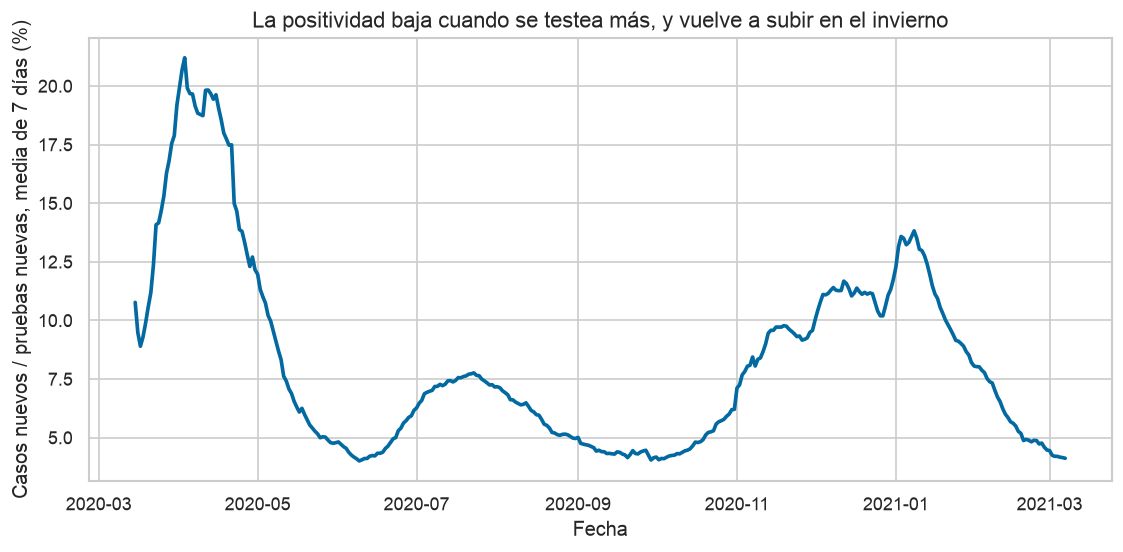

In [21]:
desde = nacional[nacional["fecha"] >= "2020-03-15"]
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(desde["fecha"], desde["positividad_7d"] * 100, color="#0369a1", linewidth=2.2)
ax.set_xlabel("Fecha")
ax.set_ylabel("Casos nuevos / pruebas nuevas, media de 7 días (%)")
ax.set_title("La positividad baja cuando se testea más, y vuelve a subir en el invierno")
guardar(fig, "12_positividad.png")

## 11. Comparar con justicia, y comparar regiones

El gráfico de la izquierda es el que vería alguien que ordene la hoja de cálculo por la columna de muertes. El de la derecha divide por la población. No es un ajuste decorativo: salen y entran estados.

La serie regional usa la misma idea en el tiempo. Cada muerte nueva se divide por la población de la región y se suaviza a 7 días. Así se ve que la primavera de 2020 fue un golpe del Noreste, y que el invierno llegó a las cuatro regiones a la vez.

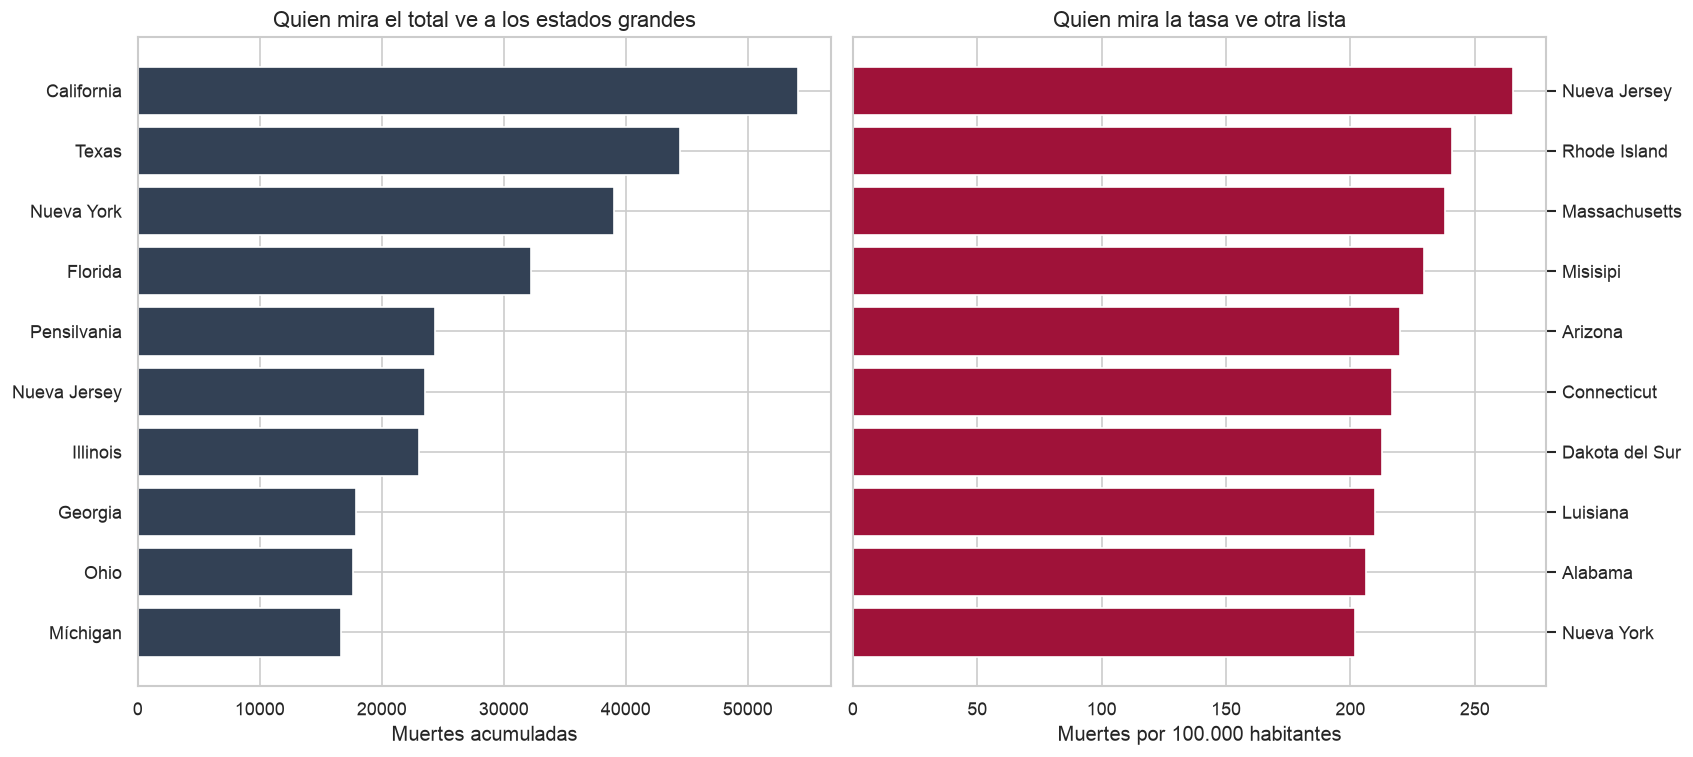

Estados que están en los dos top 10: ['NJ', 'NY']


In [22]:
bruto = foto.nlargest(10, "death").sort_values("death")
tasa = foto.nlargest(10, "muertes_por_100k").sort_values("muertes_por_100k")
fig, ejes = plt.subplots(1, 2, figsize=(14, 6.2), constrained_layout=True)
ejes[0].barh(bruto["nombre"], bruto["death"], color="#334155")
ejes[1].barh(tasa["nombre"], tasa["muertes_por_100k"], color="#9f1239")
ejes[1].yaxis.tick_right()
ejes[0].set_xlabel("Muertes acumuladas")
ejes[1].set_xlabel("Muertes por 100.000 habitantes")
ejes[0].set_title("Quien mira el total ve a los estados grandes")
ejes[1].set_title("Quien mira la tasa ve otra lista")
guardar(fig, "13_ranking_bruto_vs_tasa.png")

comunes = set(foto.nlargest(10, "death")["state"]) & set(foto.nlargest(10, "muertes_por_100k")["state"])
print("Estados que están en los dos top 10:", sorted(comunes))

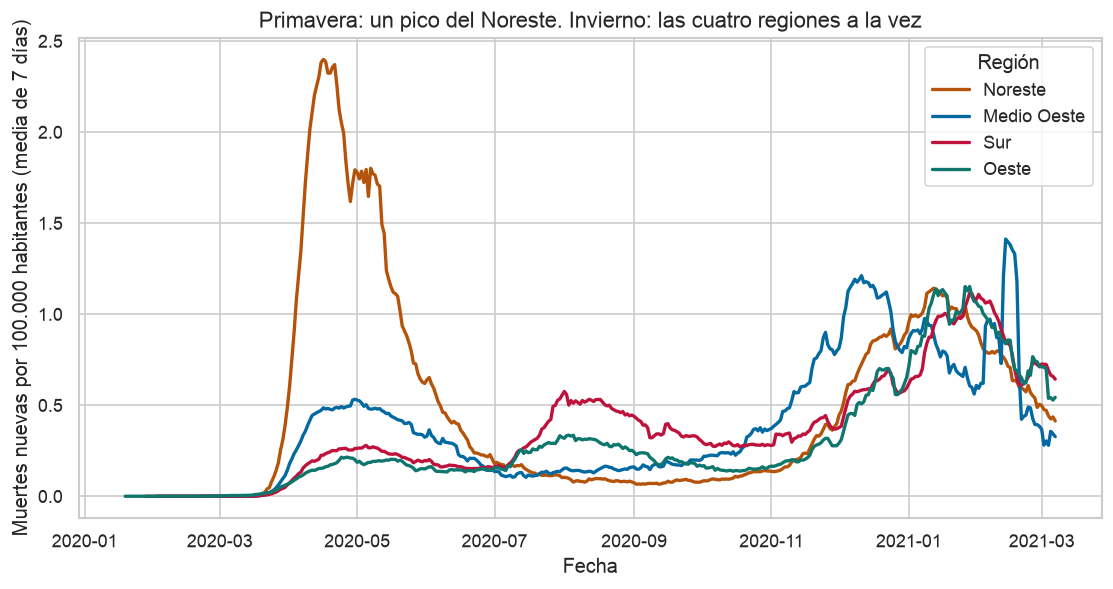

In [23]:
panel = df[df["region"].isin(REGIONES)]
poblacion_region = panel.drop_duplicates("state").groupby("region")["poblacion_2020"].sum()
diarias = panel.groupby(["fecha", "region"])["deathIncrease"].sum().unstack()
tasa_region = diarias.div(poblacion_region) * 100_000
tasa_mm7 = tasa_region.apply(media_movil)

fig, ax = plt.subplots(figsize=(11, 5.2))
for region in REGIONES:
    ax.plot(tasa_mm7.index, tasa_mm7[region], label=region, color=COLORES_REGION[region], linewidth=2)
ax.set_xlabel("Fecha")
ax.set_ylabel("Muertes nuevas por 100.000 habitantes (media de 7 días)")
ax.set_title("Primavera: un pico del Noreste. Invierno: las cuatro regiones a la vez")
ax.legend(title="Región")
guardar(fig, "14_regiones.png")

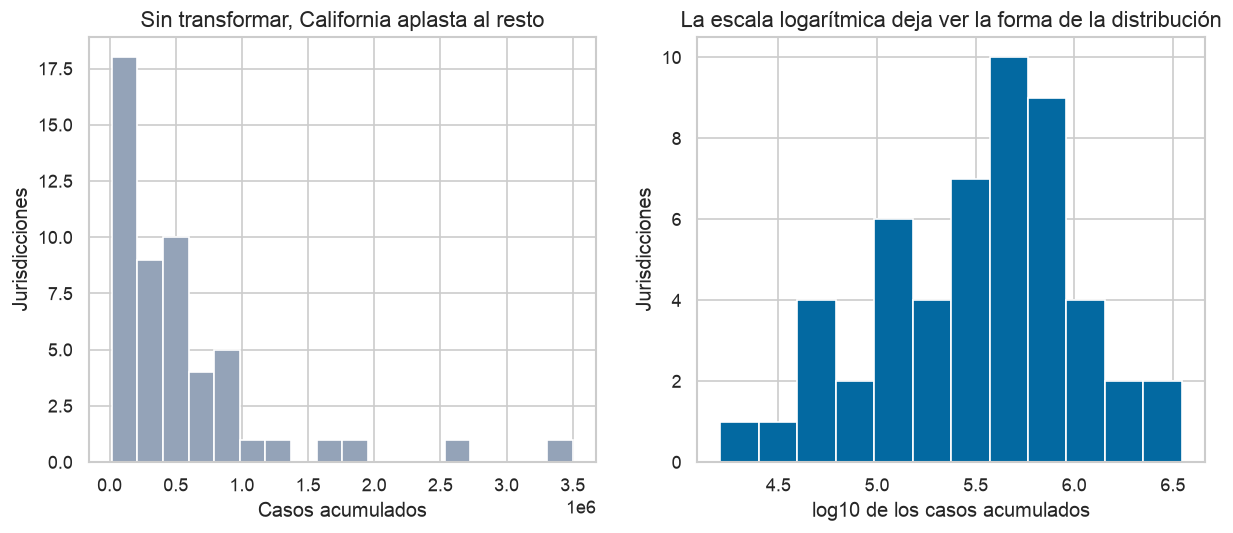

In [24]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.6))
ejes[0].hist(foto["positive"], bins=18, color="#94a3b8", edgecolor="white")
ejes[0].set_xlabel("Casos acumulados")
ejes[0].set_ylabel("Jurisdicciones")
ejes[0].set_title("Sin transformar, California aplasta al resto")
casos = foto.loc[foto["positive"] > 0, "positive"]
ejes[1].hist(np.log10(casos), bins=12, color="#0369a1", edgecolor="white")
ejes[1].set_xlabel("log10 de los casos acumulados")
ejes[1].set_ylabel("Jurisdicciones")
ejes[1].set_title("La escala logarítmica deja ver la forma de la distribución")
guardar(fig, "15_escala_log.png")

## 12. Datos de los que no hay que fiarse del todo

Tres comprobaciones, no opiniones:

- La suma de `deathIncrease`, negativos incluidos, coincide con las muertes acumuladas del 7 de marzo. Por eso las correcciones no se tiran. En los casos el cuadre falla por unas decenas: el acumulado de `positive` queda un poco por encima de la suma de `positiveIncrease`.
- `hospitalizedCurrently` casi no existe al principio de la serie y en algunos estados (Florida entre ellos) falta durante una parte larga del año. Sumar hospitalizados en abril de 2020 infraestima el país porque muchos estados todavía no publicaban la cifra.
- Los cuatro territorios sin población del censo suman muy pocas muertes en este archivo. No mueven el total nacional, y no entran en las tasas.

Suma de deathIncrease: 515151
Muertes acumuladas el último día: 515151
Suma de positiveIncrease: 28756393
Casos acumulados el último día: 28756489
Diferencia de casos: 96


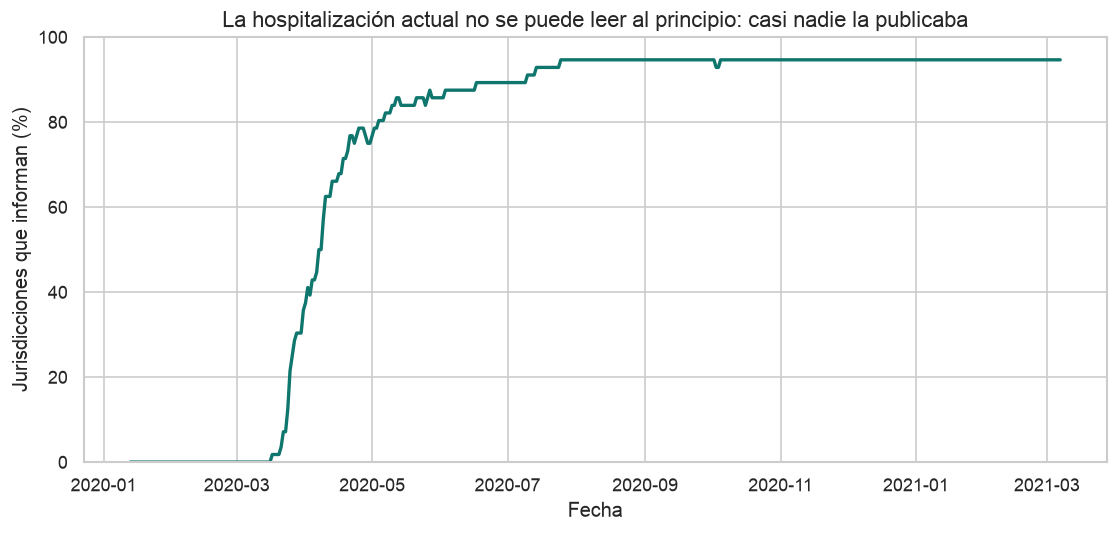

Jurisdicciones con más huecos en hospitalizados actuales:
state
MP   100.00
AS   100.00
VI    99.20
FL    40.30
KS    38.40
HI    35.80
NE    27.60
SC    21.10
Name: hospitalizedCurrently, dtype: float64


In [25]:
ultimo = df[df["fecha"] == df["fecha"].max()]
print("Suma de deathIncrease:", int(df["deathIncrease"].sum()))
print("Muertes acumuladas el último día:", int(ultimo["death"].sum()))
print("Suma de positiveIncrease:", int(df["positiveIncrease"].sum()))
print("Casos acumulados el último día:", int(ultimo["positive"].sum()))
print("Diferencia de casos:", int(ultimo["positive"].sum() - df["positiveIncrease"].sum()))

cobertura = df.groupby("fecha")["hospitalizedCurrently"].apply(lambda serie: serie.notna().mean() * 100)
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.plot(cobertura.index, cobertura.values, color="#0f766e", linewidth=2)
ax.set_xlabel("Fecha")
ax.set_ylabel("Jurisdicciones que informan (%)")
ax.set_ylim(0, 100)
ax.set_title("La hospitalización actual no se puede leer al principio: casi nadie la publicaba")
guardar(fig, "16_cobertura_hospitalizados.png")

nulos_hosp = df.groupby("state")["hospitalizedCurrently"].apply(lambda serie: serie.isna().mean() * 100)
print("Jurisdicciones con más huecos en hospitalizados actuales:")
print(nulos_hosp.sort_values(ascending=False).head(8).round(1))

## 13. Vista interactiva

El gráfico estático obliga a elegir un top 10. Este deja las 52 jurisdicciones con población, ordenadas por muertes por 100.000 habitantes, con el color de la región. El HTML queda en `reports/figuras/muertes_por_100k.html`.

In [26]:
fig = px.bar(
    foto.sort_values("muertes_por_100k"),
    x="muertes_por_100k",
    y="nombre",
    color="region",
    orientation="h",
    color_discrete_map=COLORES_REGION,
    hover_data={"death": ":,.0f", "casos_por_100k": ":,.0f", "poblacion_2020": ":,.0f", "nombre": False},
    labels={
        "muertes_por_100k": "Muertes por 100.000 habitantes",
        "nombre": "",
        "region": "Región",
        "death": "Muertes",
        "casos_por_100k": "Casos por 100.000",
        "poblacion_2020": "Población",
    },
    title="Muertes por 100.000 habitantes al 7 de marzo de 2021",
    template="simple_white",
    height=1100,
)
fig.update_layout(yaxis={"categoryorder": "total ascending"}, margin={"l": 150})
fig.write_html(FIG / "muertes_por_100k.html", include_plotlyjs="cdn")
fig.show()

## 14. Qué responden los datos

Las cifras exactas salen de la celda siguiente, calculadas sobre la tabla limpia. La lectura, en una frase cada una:

1. **El total mide el tamaño.** California encabeza las muertes acumuladas y no entra en las diez jurisdicciones con más muertes por habitante. En los dos top 10 solo coinciden Nueva York y Nueva Jersey. Nueva Jersey pasa a ser la primera cuando se divide por la población.
2. **El invierno fue la peor ola del país, y la primavera fue la peor ola del Noreste.** Enero de 2021 concentra más muertes que abril de 2020. En tasa diaria por habitante, el pico del Noreste está a mediados de abril de 2020 y casi duplica lo que cualquier región sufrió en el invierno. En enero de 2021 las cuatro regiones están altas a la vez: por eso el total nacional es mayor.
3. **Más casos por habitante no implican más muertes por habitante.** Utah combina una de las tasas de casos más altas con una letalidad aparente muy baja. Nueva Jersey tiene menos casos por habitante y muchas más muertes por habitante. Este archivo no trae la edad de la población, y sin eso no se puede explicar el hueco. Lo que sí se puede decir es que no se explica solo por «haber tenido más casos».
4. **No se decide con las columnas vacías, ni con el parte de un lunes, ni con el total de un estado grande.** Más del 80% de nulos se descartó. Los negativos se conservaron porque son el ajuste que hace cuadrar las muertes. La hospitalización de la primavera no es comparable con la del invierno.

In [27]:
def miles(valor: float) -> str:
    return f"{valor:,.0f}".replace(",", ".")

def coma(valor: float, decimales: int = 1) -> str:
    return f"{valor:,.{decimales}f}".replace(",", "X").replace(".", ",").replace("X", ".")

pico_muertes = nacional.loc[nacional["muertes_mm7"].idxmax()]
pico_casos = nacional.loc[nacional["casos_mm7"].idxmax()]
pico_region = {
    region: tasa_mm7[region].idxmax()
    for region in REGIONES
}
puestos = foto.assign(
    puesto_bruto=foto["death"].rank(ascending=False),
    puesto_tasa=foto["muertes_por_100k"].rank(ascending=False),
)
fila = lambda sigla: foto.loc[foto["state"] == sigla].iloc[0]
nj, ny, ca, ut, hi = (fila(sigla) for sigla in ["NJ", "NY", "CA", "UT", "HI"])
abril = int(por_mes.loc[por_mes["mes"] == "2020-04", "muertes"].item())
enero = int(por_mes.loc[por_mes["mes"] == "2021-01", "muertes"].item())
corr_bruta = float(foto[["positive", "death"]].corr().loc["positive", "death"])
corr_tasa_val = float(foto[["casos_por_100k", "muertes_por_100k"]].corr().loc["casos_por_100k", "muertes_por_100k"])
corr_letalidad = float(foto[["casos_por_100k", "letalidad_aparente"]].corr().loc["casos_por_100k", "letalidad_aparente"])

texto = f'''
**Comprobación de las cuatro respuestas**

- Nueva Jersey: {coma(nj["muertes_por_100k"])} muertes por 100.000, con {miles(nj["death"])} muertes. California: {miles(ca["death"])} muertes y {coma(ca["muertes_por_100k"])} por 100.000. Nueva York: {coma(ny["muertes_por_100k"])} por 100.000.
- Hawái, en el extremo bajo: {coma(hi["muertes_por_100k"])} por 100.000. Utah: {coma(ut["casos_por_100k"], 0)} casos por 100.000 y letalidad aparente del {coma(ut["letalidad_aparente"] * 100, 2)} %. Nueva Jersey: letalidad aparente del {coma(nj["letalidad_aparente"] * 100, 2)} %.
- Pico nacional de la media de 7 días: {pico_muertes["fecha"].date()} con {miles(pico_muertes["muertes_mm7"])} muertes diarias. Pico de casos: {pico_casos["fecha"].date()} con {miles(pico_casos["casos_mm7"])} casos diarios.
- Abril de 2020: {miles(abril)} muertes nuevas. Enero de 2021: {miles(enero)}.
- Pico regional (media de 7 días): Noreste el {pico_region["Noreste"].date()}, Medio Oeste el {pico_region["Medio Oeste"].date()}, Sur el {pico_region["Sur"].date()}, Oeste el {pico_region["Oeste"].date()}.
- Correlación casos-muertes en totales: {coma(corr_bruta, 2)}. En tasas: {coma(corr_tasa_val, 2)}. Casos por habitante contra letalidad aparente: {coma(corr_letalidad, 2)}.
'''
display(Markdown(texto))

import json
resumen = {
    "filas": int(crudo.shape[0]),
    "columnas_origen": int(crudo.shape[1]),
    "jurisdicciones": int(crudo["state"].nunique()),
    "fecha_min": str(df["fecha"].min().date()),
    "fecha_max": str(df["fecha"].max().date()),
    "muertes": int(df["deathIncrease"].sum()),
    "muertes_ultimo_dia": int(ultimo["death"].sum()),
    "casos_incremento": int(df["positiveIncrease"].sum()),
    "casos_ultimo_dia": int(ultimo["positive"].sum()),
    "abril_2020": abril,
    "enero_2021": enero,
    "pico_muertes_fecha": str(pico_muertes["fecha"].date()),
    "pico_muertes_mm7": round(float(pico_muertes["muertes_mm7"]), 1),
    "pico_casos_fecha": str(pico_casos["fecha"].date()),
    "pico_casos_mm7": round(float(pico_casos["casos_mm7"]), 1),
    "pico_region": {region: str(momento.date()) for region, momento in pico_region.items()},
    "nj_100k": round(float(nj["muertes_por_100k"]), 1),
    "ny_100k": round(float(ny["muertes_por_100k"]), 1),
    "ca_100k": round(float(ca["muertes_por_100k"]), 1),
    "ca_muertes": int(ca["death"]),
    "hi_100k": round(float(hi["muertes_por_100k"]), 1),
    "ut_casos_100k": round(float(ut["casos_por_100k"]), 1),
    "ut_letalidad": round(float(ut["letalidad_aparente"]), 4),
    "nj_letalidad": round(float(nj["letalidad_aparente"]), 4),
    "corr_bruta": round(corr_bruta, 2),
    "corr_tasa": round(corr_tasa_val, 2),
    "corr_letalidad": round(corr_letalidad, 2),
    "top10_comun": sorted(comunes),
    "columnas_casi_vacias": informe["casi_vacias"],
    "sin_poblacion": sin_poblacion,
}
(ROOT / "reports" / "resumen.json").write_text(json.dumps(resumen, ensure_ascii=False, indent=2), encoding="utf-8")
puestos.nsmallest(8, "puesto_bruto")[["nombre", "death", "puesto_bruto", "muertes_por_100k", "puesto_tasa"]]


**Comprobación de las cuatro respuestas**

- Nueva Jersey: 265,4 muertes por 100.000, con 23.574 muertes. California: 54.124 muertes y 137,5 por 100.000. Nueva York: 201,8 por 100.000.
- Hawái, en el extremo bajo: 31,6 por 100.000. Utah: 11.534 casos por 100.000 y letalidad aparente del 0,53 %. Nueva Jersey: letalidad aparente del 2,90 %.
- Pico nacional de la media de 7 días: 2021-01-13 con 3.335 muertes diarias. Pico de casos: 2021-01-11 con 247.111 casos diarios.
- Abril de 2020: 55.315 muertes nuevas. Enero de 2021: 95.387.
- Pico regional (media de 7 días): Noreste el 2020-04-16, Medio Oeste el 2021-02-13, Sur el 2021-01-28, Oeste el 2021-01-28.
- Correlación casos-muertes en totales: 0,97. En tasas: 0,63. Casos por habitante contra letalidad aparente: -0,09.


,nombre,death,puesto_bruto,muertes_por_100k,puesto_tasa
5,California,"54,124.00",1.00,137.48,29.00
47,Texas,"44,451.00",2.00,151.40,24.00
37,Nueva York,"39,029.00",3.00,201.84,10.00
10,Florida,"32,266.00",4.00,148.46,27.00
41,Pensilvania,"24,349.00",5.00,190.48,12.00
34,Nueva Jersey,"23,574.00",6.00,265.40,1.00
16,Illinois,"23,014.00",7.00,182.83,14.00
11,Georgia,"17,906.00",8.00,167.19,20.00
